In [1]:
# Imports
import os
from model_handler.resnet import resnet
from dataset_handler.pascal import PascalDataset
from heatmap_handler import get_lrp_methods
from model_handler import device
from utils.utils import SquareCropAndResize, imagenet_transform, inverse_transform, sam_predict, mask_transform
from prompt_handler.max_value import MaxValue
from prompt_handler.dummy import Dummy
from segment_anything import sam_model_registry, SamPredictor
from PIL import Image
from utils.xai_visualizer import Visualizer
from segment_eval_handler.iou import IOU
from heatmap_handler.lrp import simpleLRP

In [2]:
# Handler Loader
model = resnet(4)
dataset = PascalDataset(device, imagenet_transform, inverse_transform, target_transform=mask_transform)
xai_methods = [simpleLRP]
point_generator = MaxValue()
segment_eval = IOU()

In [3]:
# SAM
sam_checkpoint = os.environ.get('SAM_CHECKPOINT', 'checkpoints/sam_vit_b_01ec64.pth')
model_type = "vit_b"
sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam = sam.to(device)

/home/jovyan/Documents/personal/automatic-image-segmentation/.venv/lib/python3.12/site-packages/segment_anything/build_sam.py:105: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature

In [4]:
SAMPLES = 3
MULTIPLE_RESULTS = True

data = dataset.get_samples(SAMPLES)
for i in data:
    predictor = SamPredictor(sam)
    predictor.set_image(i.original_image)
    i.sam_predictor = predictor

In [5]:

for indx, entry in enumerate(data):
    # init xai method
    method = xai_methods[0](model)
    # generate initial heatmap (and model classification label)
    method(entry)
    # generate points prompts (updates heatmap if interpolated)
    point_generator(entry)
    sam_predict(entry, MULTIPLE_RESULTS)
    # print(entry)
    segment_eval(entry)
    print(entry)
    # print(entry)




{'original_image': (224, 270, 3),
'original_image_tensor': torch.Size([1, 3, 224, 270]),
'original_image_class': 'sheep',
'mask': (224, 270),
'sam_predictor': True,
'predicted_class_id': 348,
'predicted_class_label': 'ram, tup',
'heatmap': (7, 9),
'points': array([[185,  93]]),
'point_labels': array([1]),
'bounding_boxes': None,
'text_prompt': None,
'segmentation_count': 3,
'segmentation_masks': True,
'segmentation_scores': [0.9760399, 0.9478191, 0.9004763],
'segmentation_logits': True,
'segmentation_evaluation': [0.7266700662927078, 0.8905869116819801, 0.896059718416328],}
{'original_image': (224, 336, 3),
'original_image_tensor': torch.Size([1, 3, 224, 336]),
'original_image_class': 'bird',
'mask': (224, 336),
'sam_predictor': True,
'predicted_class_id': 100,
'predicted_class_label': 'black swan, Cygnus atratus',
'heatmap': (7, 11),
'points': array([[185,  93]]),
'point_labels': array([1]),
'bounding_boxes': None,
'text_prompt': None,
'segmentation_count': 3,
'segmentation_masks': Tr

{'original_image': (224, 298, 3),
'original_image_tensor': torch.Size([1, 3, 224, 298]),
'original_image_class': 'cow',
'mask': (224, 298),
'sam_predictor': True,
'predicted_class_id': 339,
'predicted_class_label': 'sorrel',
'heatmap': (7, 10),
'points': array([[116, 131]]),
'point_labels': array([1]),
'bounding_boxes': None,
'text_prompt': None,
'segmentation_count': 3,
'segmentation_masks': True,
'segmentation_scores': [0.9268149, 0.7391067, 0.70382583],
'segmentation_logits': True,
'segmentation_evaluation': [0.8788183532369579, 0.47839342523860023, 0.05945499587118084],}


(32.0, 30.0)
(7, 9)
(224, 270, 3)
(32.0, 30.545454545454547)
(7, 11)
(224, 336, 3)
(32.0, 29.8)
(7, 10)
(224, 298, 3)


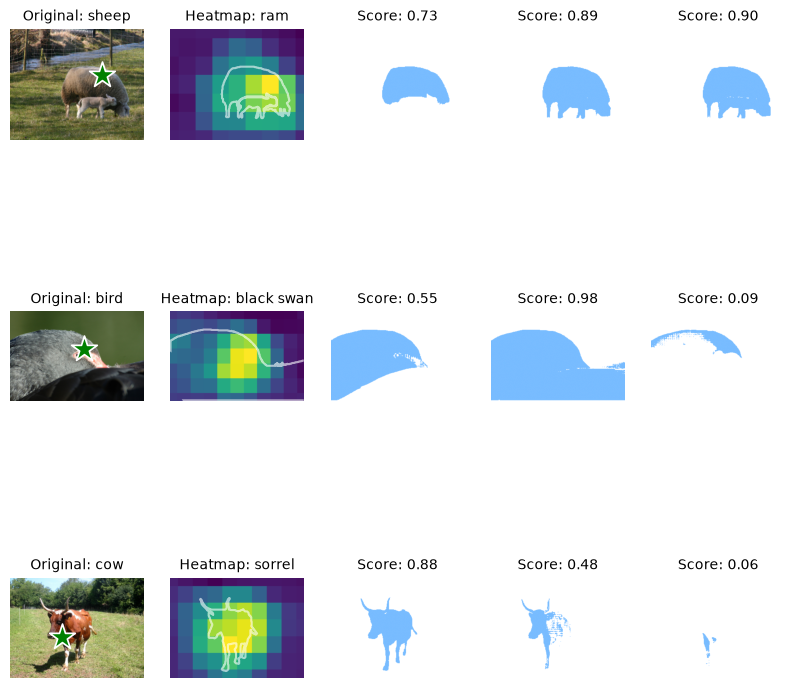

In [6]:
v = Visualizer(data)